# What AI Skills Should India Train For?

## Key findings at a glance
- **India is the world's second-biggest user of Claude.ai**, with about 7% of
  all conversations, behind only the US.
- **Almost half of India's AI use is coding.** Coding and app-building make up
  about 45% of Indian usage, much more than in the US or Brazil.
- **The same 10 coding tasks take up 38% of India's AI use**, compared with 20%
  in Brazil and 15% in the US.
- **Outside of coding, India looks a lot like the US.** When Indian users use AI
  for writing, studying or research, the mix is very similar to Americans.
- **Indian users learn with AI less.** About 14% of Indian conversations are
  about understanding something, compared with 21% in the US.

**In short:** India's AI use isn't weak, it's narrow. The biggest opportunity
seems to be using AI to learn and to work beyond coding, not just to get code
fixed.

## Why I did this
AI is quickly changing what work looks like. Tasks like writing code, drafting
documents and analysing data are now often done with AI's help, which means
the skills people need at work are changing too.

India is a big part of this story. It has one of the largest workforces in the
world, a huge tech industry, and, as this data shows, one of the biggest groups
of AI users anywhere. But most of what we read about how people use AI is
based on the US and Europe. There's much less about what Indian users actually
do with it.

That gap matters. If we don't know how people in India use AI today, it's hard
to know which skills they're building, which ones they're missing, and where
they might fall behind other countries.

I'm also someone starting my career in India, so this question feels personal.
I wanted to use real usage data, not opinions or surveys, to see what Indian
users really do with AI, how that compares with other countries, and which
skills look worth focusing on.

## What I'm looking at
1. How much of the world's AI usage comes from India?
2. What broad kinds of work do Indian users bring to AI?
3. What are the 10 specific tasks Indian users ask AI to help with most?
4. How does that list compare with the US and with a similar country like Brazil?
5. Which tasks are common in other countries but rare in India?
6. Do Indian users work with AI differently? For example, do they hand over
   the whole task, or go back and forth with it?
7. Based on all this, which AI skills should Indian working professionals
   focus on learning?

## The data
I'm using the Anthropic Economic Index (September 2025 release). It covers one
week of Claude.ai conversations, from August 4 to 11, 2025, grouped by country
and by task.

One thing to keep in mind: this only covers people using Claude, not every AI
tool. So it's a sample of AI users, not the full picture.

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/tishasharma1/anthropic-economic-index/aei_raw_claude_ai_2025-08-04_to_2025-08-11.csv


In [2]:
import pandas as pd
pd.set_option("display.max_colwidth", None)
df = pd.read_csv("/kaggle/input/datasets/tishasharma1/anthropic-economic-index/aei_raw_claude_ai_2025-08-04_to_2025-08-11.csv",
                 keep_default_na=False, na_values=[""])

print(df.shape)
df.head(10)

(100062, 10)


,geo_id,geography,date_start,date_end,platform_and_product,facet,level,variable,cluster_name,value
0,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_count,not_classified,25.000000
1,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_pct,not_classified,62.500000
2,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_count,task iteration,15.000000
3,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_pct,task iteration,37.500000
4,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),country,0,usage_count,NaN,40.000000
5,AD,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),country,0,usage_pct,NaN,0.004147
6,AE,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_count,directive,1200.000000
7,AE,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_pct,directive,39.853869
8,AE,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_count,feedback loop,349.000000
9,AE,country,2025-08-04,2025-08-11,Claude AI (Free and Pro),collaboration,0,collaboration_pct,feedback loop,11.590834


In [3]:
print("Missing values per column:")
print(df.isnull().sum(), "\n")

print("Duplicate rows:", df.duplicated().sum())
print("Namibia rows:", (df["geo_id"] == "NA").sum())

Missing values per column:
geo_id                    0
geography                 0
date_start                0
date_end                  0
platform_and_product      0
facet                     0
level                     0
variable                  0
cluster_name            450
value                     0
dtype: int64 

Duplicate rows: 0
Namibia rows: 22


## Cleaning the data
The file has 100,062 rows and 10 columns. I checked for duplicate rows and
didn't find any.

There are 450 empty values in the cluster_name column, but that's expected.
Those are the rows showing a country's total usage, and a total doesn't belong
to any one task, so there's nothing to put there.

The one real problem I ran into was Namibia. Its country code is "NA", and
pandas treats "NA" as missing data by default, so all 22 of Namibia's rows
showed up with a blank country code. I spotted this because every row should
have a country, and when I checked the original CSV, those rows clearly said
"NA". So the file was fine; pandas just misread it. I fixed this by loading
the file with keep_default_na=False, which tells pandas to keep "NA" as
normal text.

Also worth knowing: country codes here are two letters, so India is "IN".
But "IN" is also the code for Indiana in the US-state rows. So whenever I pick
out India, I also filter for geography = "country", so Indiana doesn't sneak
into the results.

In [4]:
# My four checks
is_country   = df["geography"] == "country"
is_usage     = df["facet"] == "country"
is_percent   = df["variable"] == "usage_pct"
not_unknown  = df["geo_id"] != "not_classified"

# Keep only the rows that pass all four checks
country_share = df[is_country & is_usage & is_percent & not_unknown]

# Sort from biggest share to smallest
country_share = country_share.sort_values("value", ascending=False)

# Show the top 10
country_share[["geo_id", "value"]].head(10)

,geo_id,value
47177,US,21.586448
22541,IN,7.150278
4203,BR,3.678820
26755,JP,3.659743
29369,KR,3.658395
16627,GB,3.159584
10191,DE,2.606859
14869,FR,2.209863
6093,CA,2.117794
1299,AU,1.944336


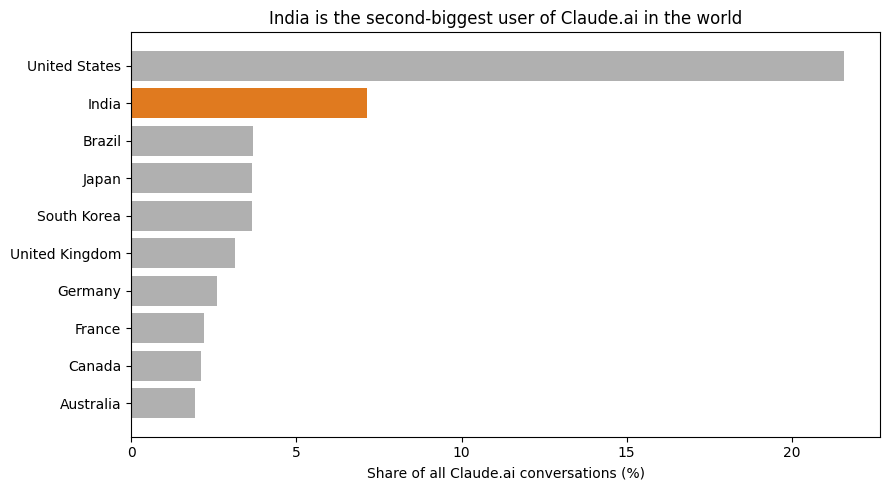

In [5]:
import matplotlib.pyplot as plt

# Top 10 countries, with full names so the chart is easy to read
top10 = country_share.head(10)
names = {"US": "United States", "IN": "India", "BR": "Brazil", "JP": "Japan",
         "KR": "South Korea", "GB": "United Kingdom", "DE": "Germany",
         "FR": "France", "CA": "Canada", "AU": "Australia"}
labels = top10["geo_id"].map(names)

# Make India stand out in a different colour
colors = ["#e07a1f" if code == "IN" else "#b0b0b0" for code in top10["geo_id"]]

plt.figure(figsize=(9, 5))
plt.barh(labels, top10["value"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Share of all Claude.ai conversations (%)")
plt.title("India is the second-biggest user of Claude.ai in the world")
plt.tight_layout()
plt.show()

## Question 1: How much of the world's AI usage comes from India?
India is the second-biggest user of Claude.ai in the world. About 7.2% of all
conversations that week came from India, behind only the US at 21.6%.

That's almost double the next countries on the list. Brazil, Japan and South
Korea each sit at around 3.7%, and the UK is at 3.2%.

One thing I want to be careful about: this is total usage, not usage per
person. India has a huge population, so a big total doesn't mean each person
uses AI a lot. What it does show is that there's a large group of Indian
professionals already using AI, which is a good sign there's a real audience
for AI skills training.

In [6]:
# My checks
is_india    = (df["geo_id"] == "IN") & (df["geography"] == "country")
is_request  = df["facet"] == "request"
is_percent  = df["variable"] == "request_pct"
is_broad    = df["level"] == 2

# Keep only India's broad request categories
india_requests = df[is_india & is_request & is_percent & is_broad]

# Sort from biggest to smallest
india_requests = india_requests.sort_values("value", ascending=False)

# Show the top 10
india_requests[["cluster_name", "value"]].head(10)

,cluster_name,value
24889,Provide comprehensive software development assistance across multiple programming domains and technologies,24.876747
24865,Help develop and debug complete web applications and user interfaces,15.969201
24891,Provide educational tutoring and academic assistance across multiple subjects and disciplines,6.267038
24869,"Help edit, improve, and create professional written documents and communications",4.915608
24899,Provide technical IT support and troubleshooting assistance,4.669103
24867,Help develop and debug cross-platform mobile applications with Flutter,3.871585
24903,not_classified,3.609129
24885,Provide comprehensive financial guidance and investment assistance across multiple domains,3.364074
24901,Provide technical and academic assistance across scientific research and educational domains,3.353924
24853,"Analyze and process data from documents, visual media, and business sources",3.220521


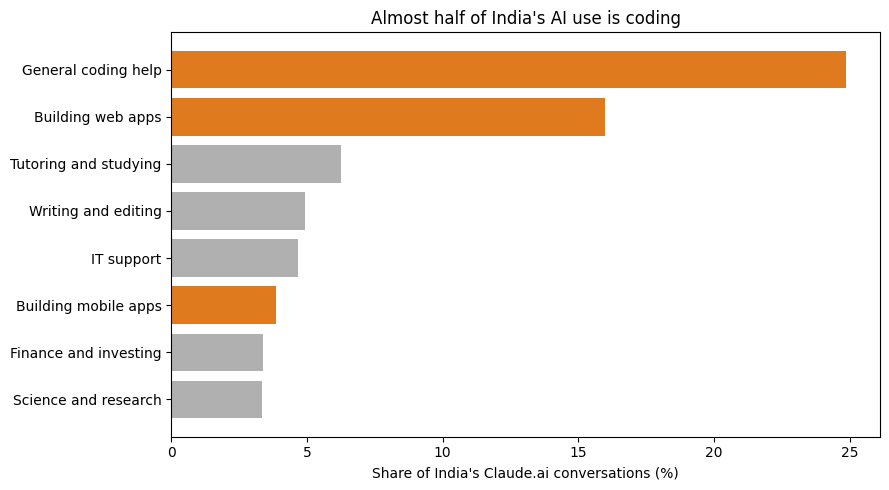

In [7]:
# India's top 8 broad categories, without the "not_classified" row
top_categories = india_requests[india_requests["cluster_name"] != "not_classified"].head(8)

# The full names are very long, so I give each one a short label
short_names = {
    "Provide comprehensive software development assistance across multiple programming domains and technologies": "General coding help",
    "Help develop and debug complete web applications and user interfaces": "Building web apps",
    "Provide educational tutoring and academic assistance across multiple subjects and disciplines": "Tutoring and studying",
    "Help edit, improve, and create professional written documents and communications": "Writing and editing",
    "Provide technical IT support and troubleshooting assistance": "IT support",
    "Help develop and debug cross-platform mobile applications with Flutter": "Building mobile apps",
    "Provide comprehensive financial guidance and investment assistance across multiple domains": "Finance and investing",
    "Provide technical and academic assistance across scientific research and educational domains": "Science and research",
}
labels = top_categories["cluster_name"].map(short_names)

# Coding categories in orange, everything else in grey
coding_labels = ["General coding help", "Building web apps", "Building mobile apps"]
colors = ["#e07a1f" if label in coding_labels else "#b0b0b0" for label in labels]

plt.figure(figsize=(9, 5))
plt.barh(labels, top_categories["value"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Share of India's Claude.ai conversations (%)")
plt.title("Almost half of India's AI use is coding")
plt.tight_layout()
plt.show()

## Question 2: What broad kinds of work do Indian users bring to AI?
Most of it is tech work. General coding help is the biggest category on its
own at about 25%, followed by building web apps at 16%. Add mobile app
development (3.9%) and those three alone make up almost half of all Indian
usage, around 45%. With IT support included, it's close to 50%.

Everything else is much smaller. Studying and tutoring comes next at about 6%,
then writing and editing documents at about 5%. Finance, science and research,
and data analysis each sit at around 3%.

So the picture is clear: in India, AI is mainly being used as a coding tool.
Other kinds of work, like writing, analysis and research, are still a small
part of how people use it. Whether that's different from other countries is
what I want to look at next.

(About 3.6% of conversations couldn't be put into any category, so I've left
those out of this summary.)

In [8]:
# My checks
is_india     = (df["geo_id"] == "IN") & (df["geography"] == "country")
is_task      = df["facet"] == "onet_task"
is_percent   = df["variable"] == "onet_task_pct"
not_unknown  = df["cluster_name"] != "not_classified"
not_none     = df["cluster_name"] != "none"

# Keep only India's real tasks
india_tasks = df[is_india & is_task & is_percent & not_unknown & not_none]

# Sort from biggest to smallest and show the top 10
india_tasks = india_tasks.sort_values("value", ascending=False)
india_tasks[["cluster_name", "value"]].head(10)

,cluster_name,value
23459,"write new programs or modify existing programs to meet customer requirements, using current programming languages and technologies.",9.596311
23059,"modify existing software to correct errors, allow it to adapt to new hardware, or to improve its performance.",7.421263
23061,"modify existing software to correct errors, to adapt it to new hardware, or to upgrade interfaces and improve performance.",5.211415
22747,correct errors by making appropriate changes and rechecking the program to ensure that the desired results are produced.,3.861435
22801,"design, build, or maintain web sites, using authoring or scripting languages, content creation tools, management tools, and digital media.",3.858535
22921,"diagnose, troubleshoot, and resolve hardware, software, or other network and system problems, and replace defective components when necessary.",2.321501
23487,"write, update, and maintain computer programs or software packages to handle specific jobs such as tracking inventory, storing or retrieving data, or controlling other equipment.",1.506583
23089,"perform initial debugging procedures by reviewing configuration files, logs, or code pieces to determine breakdown source.",1.407981
23337,"review and analyze computer printouts and performance indicators to locate code problems, and correct errors by correcting codes.",1.338379
23097,"perform routine system administrative functions such as troubleshooting, back-ups, and upgrades.",1.248477


## Question 3: What are the 10 specific tasks Indian users ask AI to help with most?
Zooming in on specific tasks makes the pattern from Question 2 even clearer.
All 10 of India's top tasks are about coding or IT. The biggest is writing new
programs or changing existing ones, at about 9.6% of usage.

What surprised me is how much of it is about fixing things. Five of the top 10
tasks are about finding and correcting errors in code, debugging, or improving
software that already exists. So a lot of Indian users seem to use AI less as
a way to build from scratch and more as a debugging partner.

Together, these 10 tasks make up about 38% of all Indian usage. No writing,
teaching, business or analysis task made it into the top 10.

A small note: some tasks look almost the same, like the two about changing
software to fix errors. That's because the task list (O*NET) describes tasks
for different jobs separately, so similar tasks sometimes appear twice with
slightly different wording.

Before this, I removed two rows that aren't real tasks: "not_classified"
(conversations that couldn't be matched to a task, about 10.8%) and "none"
(conversations not about a work task, about 2.5%).

In [9]:
# My checks, this time for three countries at once
three_countries = df["geo_id"].isin(["IN", "US", "BR"])
is_country      = df["geography"] == "country"
is_task         = df["facet"] == "onet_task"
is_percent      = df["variable"] == "onet_task_pct"
real_task       = ~df["cluster_name"].isin(["not_classified", "none"])

tasks = df[three_countries & is_country & is_task & is_percent & real_task]

# Put the three countries side by side: one row per task, one column per country
comparison = tasks.pivot_table(index="cluster_name", columns="geo_id", values="value")

# Sort by India and show India's top 10, with the US and Brazil next to it
comparison.sort_values("IN", ascending=False).head(10).round(1)

geo_id,BR,IN,US
cluster_name,,,
"write new programs or modify existing programs to meet customer requirements, using current programming languages and technologies.",4.6,9.6,2.9
"modify existing software to correct errors, allow it to adapt to new hardware, or to improve its performance.",3.8,7.4,2.0
"modify existing software to correct errors, to adapt it to new hardware, or to upgrade interfaces and improve performance.",2.7,5.2,1.5
correct errors by making appropriate changes and rechecking the program to ensure that the desired results are produced.,1.7,3.9,1.4
"design, build, or maintain web sites, using authoring or scripting languages, content creation tools, management tools, and digital media.",1.7,3.9,1.2
"diagnose, troubleshoot, and resolve hardware, software, or other network and system problems, and replace defective components when necessary.",1.6,2.3,2.0
"write, update, and maintain computer programs or software packages to handle specific jobs such as tracking inventory, storing or retrieving data, or controlling other equipment.",1.6,1.5,0.7
"perform initial debugging procedures by reviewing configuration files, logs, or code pieces to determine breakdown source.",0.6,1.4,0.6
"review and analyze computer printouts and performance indicators to locate code problems, and correct errors by correcting codes.",0.7,1.3,0.7


In [10]:
# How much of each country's usage do India's top 10 tasks make up in total?
comparison.sort_values("IN", ascending=False).head(10).sum().round(1)

geo_id
BR    19.9
IN    37.8
US    14.6
dtype: float64

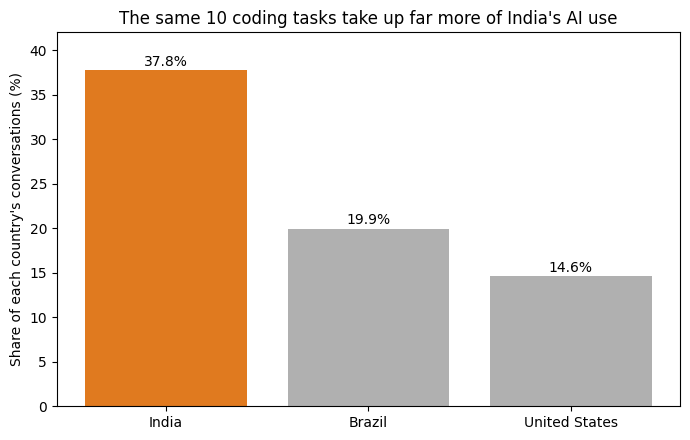

In [11]:
# Share of each country's usage taken up by India's top 10 tasks
totals = comparison.sort_values("IN", ascending=False).head(10).sum()

countries = ["India", "Brazil", "United States"]
values    = [totals["IN"], totals["BR"], totals["US"]]
colors    = ["#e07a1f", "#b0b0b0", "#b0b0b0"]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(countries, values, color=colors)

# Write the number on top of each bar
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.5,
             f"{value:.1f}%", ha="center")
plt.ylim(0, 42)
plt.ylabel("Share of each country's conversations (%)")
plt.title("The same 10 coding tasks take up far more of India's AI use")
plt.tight_layout()
plt.show()

## Question 4: How does India's list compare with the US and Brazil?
All three countries use AI for coding, but India leans on it far more.

For almost every task in India's top 10, India's share is about double
Brazil's and two to three times the US's. The biggest one, writing or changing
programs, is 9.6% of usage in India, compared with 4.6% in Brazil and 2.9% in
the US.

Added together, these 10 tasks make up about 38% of Indian usage, but only
about 20% in Brazil and 15% in the US. So coding isn't just the top use of AI
in India. It takes up a much bigger part of the picture than it does in other
countries.

The one exception is routine system admin work, like backups and upgrades,
where all three countries are roughly the same.

This made me curious about the other side: if India spends so much of its AI
use on coding, what are other countries using AI for that India isn't? That's
the next question.

In [12]:
# Broad request categories for India, the US and Brazil
three_countries = df["geo_id"].isin(["IN", "US", "BR"])
is_country      = df["geography"] == "country"
is_request      = df["facet"] == "request"
is_percent      = df["variable"] == "request_pct"
is_broad        = df["level"] == 2
is_known        = df["cluster_name"] != "not_classified"

categories = df[three_countries & is_country & is_request & is_percent & is_broad & is_known]

# Countries side by side
gaps = categories.pivot_table(index="cluster_name", columns="geo_id", values="value").fillna(0)

# How much more do the US and Brazil use each category than India?
gaps["US_minus_IN"] = gaps["US"] - gaps["IN"]
gaps["BR_minus_IN"] = gaps["BR"] - gaps["IN"]

# Biggest gaps compared with the US first
gaps.sort_values("US_minus_IN", ascending=False).round(1).head(10)

geo_id,BR,IN,US,US_minus_IN,BR_minus_IN
cluster_name,,,,,
Provide educational tutoring and academic assistance across multiple subjects and disciplines,4.4,6.3,9.6,3.3,-1.8
"Help edit, improve, and create professional written documents and communications",6.1,4.9,7.5,2.5,1.1
Provide medical and sports training guidance,1.8,1.5,3.9,2.4,0.3
Provide technical and academic assistance across scientific research and educational domains,2.7,3.4,5.6,2.2,-0.7
Provide comprehensive domestic life and household management guidance,0.8,0.8,3.0,2.2,0.0
"Provide personalized lifestyle advice and recommendations across relationships, spirituality, entertainment, beauty, and parenting",1.6,1.7,3.5,1.8,-0.1
Provide technical IT support and troubleshooting assistance,3.1,4.7,6.3,1.6,-1.6
Assist with creative writing across multiple genres including humor and romantic roleplay,1.8,0.8,2.1,1.3,1.0
Provide comprehensive financial guidance and investment assistance across multiple domains,2.5,3.4,4.7,1.3,-0.9


In [13]:
# The three coding categories
coding = [
    "Provide comprehensive software development assistance across multiple programming domains and technologies",
    "Help develop and debug complete web applications and user interfaces",
    "Help develop and debug cross-platform mobile applications with Flutter",
]

# Remove coding and keep only the three country columns
non_coding = gaps.drop(coding)[["BR", "IN", "US"]]

# Rescale so each country's non-coding usage adds up to 100% again
non_coding = non_coding / non_coding.sum() * 100

# Gaps again, now without coding in the way
non_coding["US_minus_IN"] = non_coding["US"] - non_coding["IN"]
non_coding["BR_minus_IN"] = non_coding["BR"] - non_coding["IN"]

non_coding.sort_values("US_minus_IN", ascending=False).round(1).head(10)

geo_id,BR,IN,US,US_minus_IN,BR_minus_IN
cluster_name,,,,,
Provide comprehensive domestic life and household management guidance,1.2,1.5,4.2,2.6,-0.3
Provide medical and sports training guidance,2.6,2.9,5.5,2.6,-0.3
"Provide personalized lifestyle advice and recommendations across relationships, spirituality, entertainment, beauty, and parenting",2.3,3.3,4.9,1.6,-1.0
Assist with creative writing across multiple genres including humor and romantic roleplay,2.5,1.5,2.9,1.4,1.1
Provide technical and academic assistance across scientific research and educational domains,3.8,6.5,7.8,1.3,-2.7
Provide educational tutoring and academic assistance across multiple subjects and disciplines,6.3,12.1,13.3,1.2,-5.8
"Help edit, improve, and create professional written documents and communications",8.6,9.5,10.4,0.9,-0.9
Provide comprehensive legal assistance including immigration and document services,13.3,2.1,3.0,0.8,11.1
"Help plan and organize events, schedules, and travel arrangements",1.3,2.0,2.6,0.7,-0.7


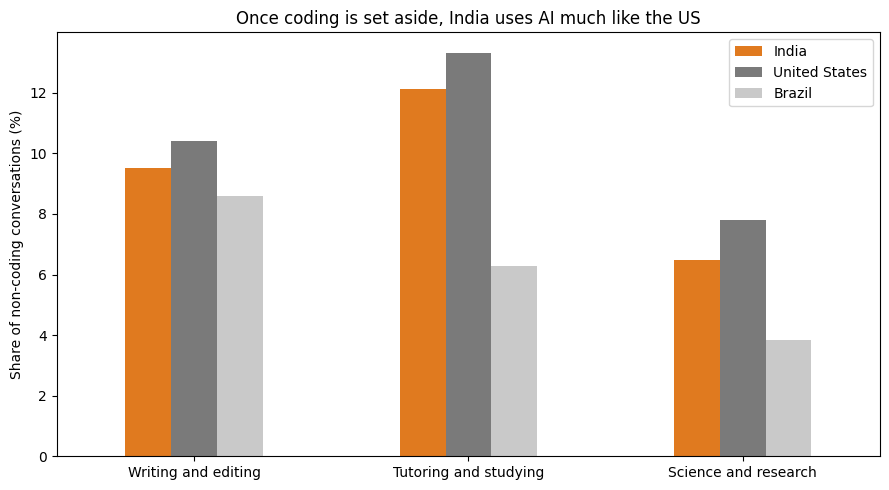

In [14]:
# Three work-related categories, after removing coding
work_categories = {
    "Help edit, improve, and create professional written documents and communications": "Writing and editing",
    "Provide educational tutoring and academic assistance across multiple subjects and disciplines": "Tutoring and studying",
    "Provide technical and academic assistance across scientific research and educational domains": "Science and research",
}

chart_data = non_coding.loc[list(work_categories), ["IN", "US", "BR"]]
chart_data = chart_data.rename(index=work_categories,
                               columns={"IN": "India", "US": "United States", "BR": "Brazil"})

chart_data.plot(kind="bar", figsize=(9, 5), color=["#e07a1f", "#7a7a7a", "#c9c9c9"])
plt.xticks(rotation=0)
plt.ylabel("Share of non-coding conversations (%)")
plt.xlabel("")
plt.title("Once coding is set aside, India uses AI much like the US")
plt.legend(title="")
plt.tight_layout()
plt.show()

## Question 5: Which tasks are common in other countries but rare in India?
At first, it looked like India was behind the US in a lot of areas: tutoring,
writing professional documents, science and research, finance, and IT support.
Writing and editing documents even looked like a gap compared with both the US
(7.5% vs 4.9%) and Brazil (6.1% vs 4.9%).

But I realised these numbers could be misleading. Each country's usage adds up
to 100%, and in India, coding alone takes up about 45% of it. That leaves less
room for everything else, so other categories would look smaller in India even
if people used AI for them just as much.

To check this, I removed the three coding categories and rescaled what was left
so it added up to 100% again. That way I could compare how each country uses AI
for everything other than coding.

The picture changed quite a bit:
- **Writing professional documents:** India 9.5%, US 10.4%, Brazil 8.6%.
  Almost the same.
- **Tutoring and studying:** India 12.1%, US 13.3%. Very close.
- **Science and research:** India 6.5%, US 7.8%, and India is ahead of Brazil.

The biggest gaps that were left were in personal life topics like household
management, health and fitness, and lifestyle advice, where Americans use AI
more.

So my takeaway is that Indian users aren't really missing skills like writing,
studying or research. When they use AI for non-coding work, they use it in a
similar way to people in the US. The real difference is how narrow India's AI
use is: coding takes up so much of it that everything else looks small.

(Brazil's high share for legal help, about 9%, looks specific to Brazil, so I
haven't treated it as a gap for India.)

In [15]:
# How people work with AI, for India, the US and Brazil
three_countries = df["geo_id"].isin(["IN", "US", "BR"])
is_country      = df["geography"] == "country"
is_collab       = df["facet"] == "collaboration"
is_percent      = df["variable"] == "collaboration_pct"

collab = df[three_countries & is_country & is_collab & is_percent]

# Countries side by side
collab_table = collab.pivot_table(index="cluster_name", columns="geo_id", values="value")
collab_table.round(1)

geo_id,BR,IN,US
cluster_name,,,
directive,54.1,43.9,37.0
feedback loop,8.7,12.9,8.3
learning,12.2,14.2,21.3
none,1.8,2.5,7.8
task iteration,20.1,23.0,21.2
validation,3.1,3.4,4.5


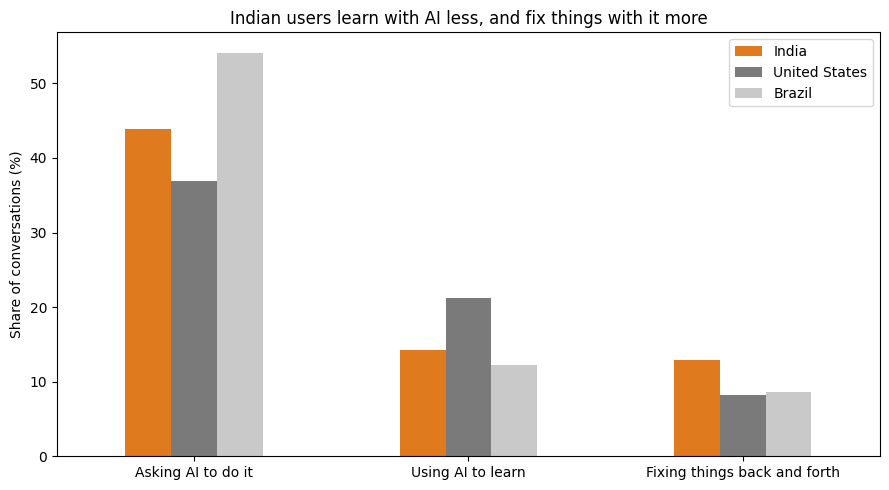

In [16]:
# The three working styles where India stands out
styles = {
    "directive": "Asking AI to do it",
    "learning": "Using AI to learn",
    "feedback loop": "Fixing things back and forth",
}

style_data = collab_table.loc[list(styles), ["IN", "US", "BR"]]
style_data = style_data.rename(index=styles,
                               columns={"IN": "India", "US": "United States", "BR": "Brazil"})

style_data.plot(kind="bar", figsize=(9, 5), color=["#e07a1f", "#7a7a7a", "#c9c9c9"])
plt.xticks(rotation=0)
plt.ylabel("Share of conversations (%)")
plt.xlabel("")
plt.title("Indian users learn with AI less, and fix things with it more")
plt.legend(title="")
plt.tight_layout()
plt.show()

## Question 6: Do Indian users work with AI differently?
Yes, in a few clear ways.

**They hand over work more often than Americans.** In about 44% of Indian
conversations, people basically asked AI to do the task for them ("directive").
In the US it's 37%. Brazil is even higher at 54%, so India sits in between.

**They use AI to learn much less.** Only about 14% of Indian conversations were
about understanding something, compared with 21% in the US. This was the
biggest difference I found here. Americans use AI as a learning tool about 1.5
times as often.

**They go back and forth to fix things more.** "Feedback loops," where someone
tries what AI gave them, comes back with the result or an error, and asks for a
fix, make up about 13% of Indian conversations. That's higher than both the US
(8%) and Brazil (9%). It matches what I saw in Question 3, where so many of
India's top tasks were about debugging.

So overall, Indian users mostly treat AI as something that does and fixes work,
and less as something that helps them understand it.

One thing to keep in mind: how people work with AI depends partly on what they
use it for. Debugging naturally involves a lot of back-and-forth, so India's
heavy coding use probably explains part of the feedback-loop difference.

## Question 7: Which AI skills should Indian working professionals focus on?
Looking at everything together, three things stand out.

**1. Using AI to learn, not just to get answers.**
This is the clearest gap in the data. Indian users use AI to understand things
in about 14% of conversations, compared with 21% in the US. At the same time,
a lot of Indian usage is about fixing code that's broken. Getting AI to fix an
error solves today's problem, but asking it to explain why the error happened
builds a skill that lasts. For the many Indian developers already using AI,
this could be the most useful habit to build.

**2. Using AI beyond coding.**
Coding takes up about 45% of India's AI use, much more than in the US or
Brazil. But when Indian users do use AI for other work, like writing documents,
studying or research, they use it in a similar way to Americans. So these
aren't skills India is missing. They're just a small part of how people use AI
today. Professionals outside tech, and developers who also write reports or
emails, may be getting much less out of AI than they could.

**3. Checking and understanding AI's work.**
Indian users hand tasks over to AI more often than Americans, and spend a lot
of time going back and forth to fix what it gives them. Knowing how to review
AI's output, spot its mistakes early and understand what it produced would
make that time far more useful.

Here's how each of these connects to what I found:

| What I found | What it suggests |
|---|---|
| Indian users use AI to learn in 14% of conversations, vs 21% in the US | Use AI to understand, not just to get answers |
| Coding is about 45% of India's AI use, much more than the US or Brazil | Use AI for more than coding |
| Without coding, India's mix looks a lot like the US | These skills aren't missing, just underused |
| More handing over and more back-and-forth fixing than the US | Learn to review and understand AI's output |

I want to be careful here: this data shows how people use AI, not what they
need or what employers want. These are areas where Indian usage looks
different from other countries, which makes them worth paying attention to,
but they aren't proof of what people should learn.

## Limitations
There are a few things this analysis can't tell us:

- **It only covers Claude users.** Many people in India use other AI tools,
  and they might use them differently.
- **It's one week of data,** from August 2025. AI use changes quickly, so the
  picture today may be different.
- **Usage isn't the same as need.** If Indians use AI less for something, it
  could mean they don't know how, or simply that they don't need it. This data
  can't tell the difference.
- **India's job market shapes the results.** India has a huge IT industry, so
  heavy coding use partly reflects the kind of work people do, not just how
  they choose to use AI.
- **I compared with two countries.** Adding more countries would make the
  comparisons stronger.

## What I'd do next
- Compare this data with a newer release, to see whether India's use of AI is
  becoming more varied over time.
- Bring in data on what employers in India are looking for, like job postings
  that mention AI skills, and see how it lines up with how people actually use
  AI.
- Use Google Trends to look at interest in AI across Indian states, since this
  dataset only has state-level data for the US.